# Educational Guide: 3D Confocal Raman Spectroscopy & Dislocation Analysis in Diamond (111)

This Jupyter Notebook provides a complete, step-by-step educational pipeline for processing and analyzing 3D confocal Raman mapping data of diamond crystals. 

### Key Educational Objectives:
1. **Data Ingestion:** Reading Renishaw `.wdf` depth series files ($Z = 0, -1, -2, -3, -4, -5$ µm).
2. **Baseline Correction:** Removing background luminescence (crucial for 785 nm laser excitation near defects).
3. **Spectral Fitting / Moment Analysis:** Extracting the primary diamond Raman peak (~1332 cm⁻¹) parameters:
   - **Intensity (Height / Zero-th moment):** Crystallinity and scattering efficiency.
   - **Center Position (First moment / Lorentzian center):** Residual mechanical stress and strain ($\Delta \omega$).
   - **FWHM Width (Second moment / Lorentzian width):** Defect density and phonon lifetime.
4. **Visualization & Tomography:** 2D spatial maps, depth cross-sections (XZ/YZ), and dislocation core identification.

## Step 0: Environment Setup & Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter
import os

# Set plotting style for scientific publications
plt.rcParams.update({'font.size': 11, 'figure.dpi': 120})
print(f"Libraries loaded successfully. NumPy: {np.__version__}")

Libraries loaded successfully. NumPy: 2.4.1


## Step 1: Loading Renishaw `.wdf` Depth Series Data

We load files corresponding to the $25 \times 25$ µm scanned area on the diamond (111) facet across 6 depth layers ($Z = 0, -1, -2, -3, -4, -5$ µm).

In [2]:
# Define paths to data files
data_dir = "../data"
file_list = [
    os.path.join(data_dir, "map_t0_P100%_Ac1_100x_25x25_1_mkm_z0.wdf"),
    os.path.join(data_dir, "map_t0_P100%_Ac1_100x_25x25_1_mkm_z-1.wdf"),
    os.path.join(data_dir, "map_t0_P100%_Ac1_100x_25x25_1_mkm_z-2.wdf"),
    os.path.join(data_dir, "map_t0_P100%_Ac1_100x_25x25_1_mkm_z-3.wdf"),
    os.path.join(data_dir, "map_t0_P100%_Ac1_100x_25x25_1_mkm_z-4.wdf"),
    os.path.join(data_dir, "map_t0_P100%_Ac1_100x_25x25_1_mkm_z-5.wdf")
]

existing_files = [f for f in file_list if os.path.exists(f)]
print(f"Found {len(existing_files)} data files out of {len(file_list)} expected layers.")

Found 6 data files out of 6 expected layers.


## Step 2: Baseline Correction & Peak Analysis Functions

Under a 785 nm laser, diamond luminescence or instrumental background can tilt the baseline. We apply a simple polynomial baseline subtraction and robust Lorentzian fitting.

In [3]:
def remove_baseline_poly(x, y, deg=2):
    """Removes background luminescence using polynomial fitting on spectral edges."""
    coeffs = np.polyfit(x, y, deg)
    baseline = np.polyval(coeffs, x)
    return np.maximum(y - baseline, 0)

def lorentzian(x, amp, center, width, offset):
    """Standard Lorentzian function for diamond Raman peak."""
    return amp * (width**2 / ((x - center)**2 + width**2)) + offset

## Step 3: Full Processing Pipeline Across All Layers

In [4]:
def process_diamond_layers(filepaths, peak_range=(1300, 1350), smoothing_sigma=1.0):
    all_spectra = []
    wavenumbers_global = None
    
    pos_layers, width_layers, int_layers = [], [], []
    
    for idx, filepath in enumerate(filepaths):
        print(f"Processing layer {idx+1}/{len(filepaths)}: {os.path.basename(filepath)}")
        try:
            from renishawWiRE import WDFReader
            reader = WDFReader(filepath)
            spectra = reader.spectra
            wavenumbers = reader.xdata
            
            if wavenumbers_global is None:
                wavenumbers_global = wavenumbers
                
            grid_y, grid_x = spectra.shape[0], spectra.shape[1]
            spectra_flat = spectra.reshape(-1, len(wavenumbers))
            all_spectra.append(spectra_flat)
            
        except Exception as e:
            print(f"Error reading {filepath}: {e}")
            continue
            
        mask = (wavenumbers >= peak_range[0]) & (wavenumbers <= peak_range[1])
        x_fit = wavenumbers[mask]
        
        n_points = spectra_flat.shape[0]
        positions = np.zeros(n_points)
        widths = np.zeros(n_points)
        intensities = np.zeros(n_points)
        
        for i in range(n_points):
            y_raw = spectra_flat[i, mask]
            y_clean = remove_baseline_poly(x_fit, y_raw)
            
            p0 = [np.max(y_clean), x_fit[np.argmax(y_clean)], 2.0, 0.0]
            try:
                popt, _ = curve_fit(lorentzian, x_fit, y_clean, p0=p0, maxfev=1500)
                positions[i] = popt[1]
                widths[i] = abs(popt[2]) * 2  # FWHM
                intensities[i] = popt[0]
            except:
                positions[i] = np.nan
                widths[i] = np.nan
                intensities[i] = np.nan
                
        # Reshape to 2D spatial grid and apply smoothing
        pos_2d = gaussian_filter(positions.reshape(grid_y, grid_x), sigma=smoothing_sigma)
        width_2d = gaussian_filter(widths.reshape(grid_y, grid_x), sigma=smoothing_sigma)
        int_2d = gaussian_filter(intensities.reshape(grid_y, grid_x), sigma=smoothing_sigma)
        
        pos_layers.append(pos_2d)
        width_layers.append(width_2d)
        int_layers.append(int_2d)
        
    results = {
        'position': np.array(pos_layers),
        'width': np.array(width_layers),
        'intensity': np.array(int_layers),
        'wavenumbers': wavenumbers_global,
        'all_spectra': np.vstack(all_spectra) if all_spectra else None
    }
    return results

if existing_files:
    results = process_diamond_layers(existing_files)
    print("\nProcessing complete! Data cube shape (Z, Y, X):", results['intensity'].shape)

Processing layer 1/6: map_t0_P100%_Ac1_100x_25x25_1_mkm_z0.wdf
Processing layer 2/6: map_t0_P100%_Ac1_100x_25x25_1_mkm_z-1.wdf
Processing layer 3/6: map_t0_P100%_Ac1_100x_25x25_1_mkm_z-2.wdf
Processing layer 4/6: map_t0_P100%_Ac1_100x_25x25_1_mkm_z-3.wdf
Processing layer 5/6: map_t0_P100%_Ac1_100x_25x25_1_mkm_z-4.wdf
Processing layer 6/6: map_t0_P100%_Ac1_100x_25x25_1_mkm_z-5.wdf

Processing complete! Data cube shape (Z, Y, X): (6, 26, 26)


## Step 4: Visualization 1 - Mean Raman Spectrum & Baseline Correction

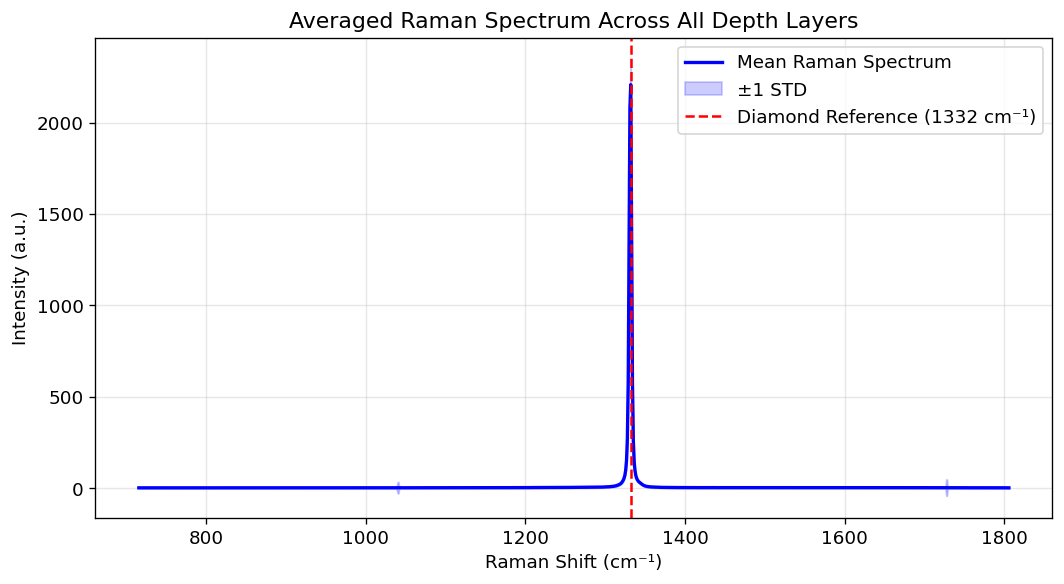

In [5]:
if 'results' in locals() and results['all_spectra'] is not None:
    mean_spec = np.mean(results['all_spectra'], axis=0)
    std_spec = np.std(results['all_spectra'], axis=0)
    wavenumbers = results['wavenumbers']
    
    plt.figure(figsize=(9, 5))
    plt.plot(wavenumbers, mean_spec, 'b-', lw=2, label='Mean Raman Spectrum')
    plt.fill_between(wavenumbers, mean_spec - std_spec, mean_spec + std_spec, color='blue', alpha=0.2, label='±1 STD')
    plt.axvline(1332, color='red', linestyle='--', label='Diamond Reference (1332 cm⁻¹)')
    plt.xlabel('Raman Shift (cm⁻¹)')
    plt.ylabel('Intensity (a.u.)')
    plt.title('Averaged Raman Spectrum Across All Depth Layers')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Step 5: Visualization 2 - Spatial Maps (Intensity, Shift/Stress, FWHM Width)

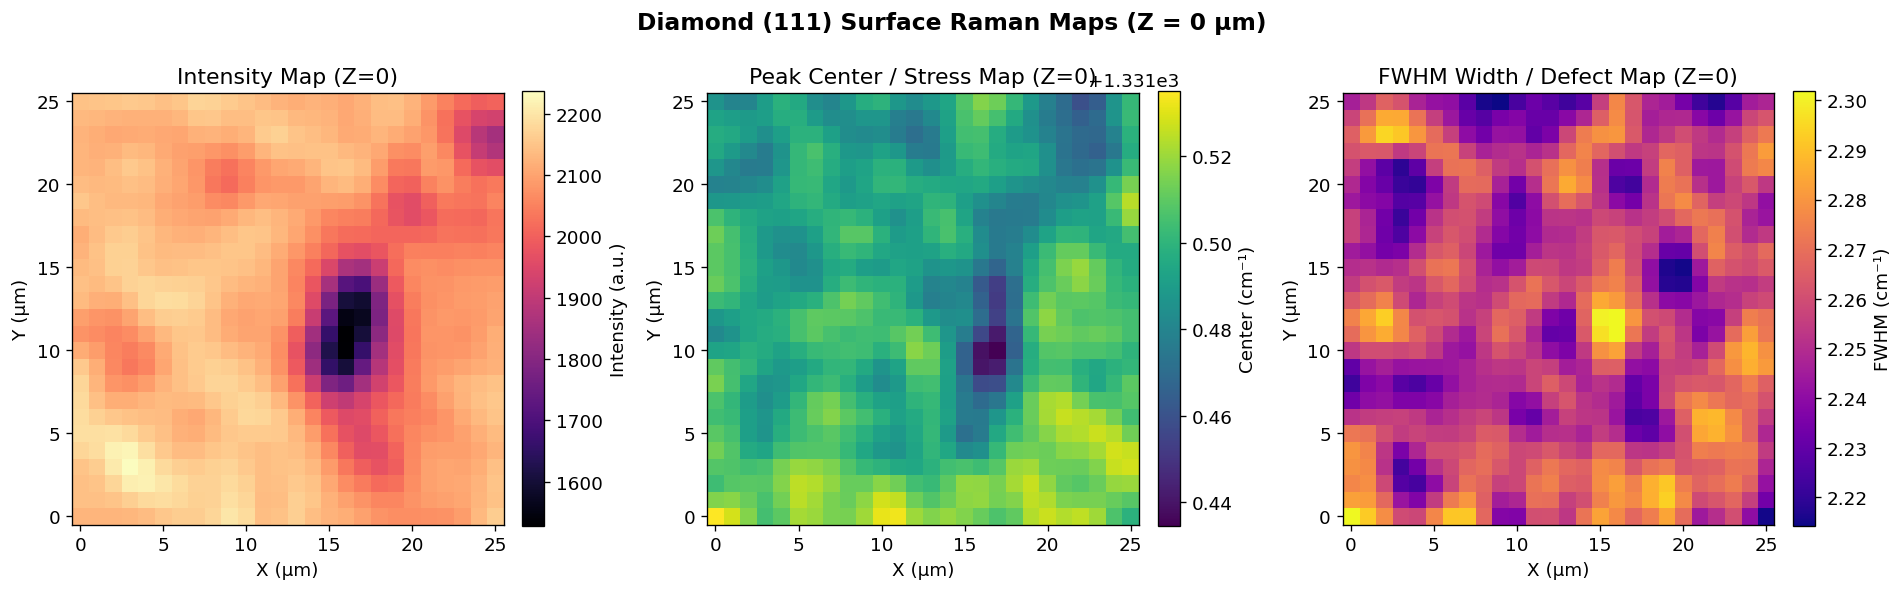

In [6]:
if 'results' in locals():
    # Select surface layer (Z=0) for demonstration
    z_idx = 0
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    im0 = axes[0].imshow(results['intensity'][z_idx], cmap='magma', origin='lower')
    axes[0].set_title(f'Intensity Map (Z={z_idx})')
    axes[0].set_xlabel('X (µm)')
    axes[0].set_ylabel('Y (µm)')
    plt.colorbar(im0, ax=axes[0], label='Intensity (a.u.)', fraction=0.046, pad=0.04)
    
    im1 = axes[1].imshow(results['position'][z_idx], cmap='viridis', origin='lower')
    axes[1].set_title(f'Peak Center / Stress Map (Z={z_idx})')
    axes[1].set_xlabel('X (µm)')
    axes[1].set_ylabel('Y (µm)')
    plt.colorbar(im1, ax=axes[1], label='Center (cm⁻¹)', fraction=0.046, pad=0.04)
    
    im2 = axes[2].imshow(results['width'][z_idx], cmap='plasma', origin='lower')
    axes[2].set_title(f'FWHM Width / Defect Map (Z={z_idx})')
    axes[2].set_xlabel('X (µm)')
    axes[2].set_ylabel('Y (µm)')
    plt.colorbar(im2, ax=axes[2], label='FWHM (cm⁻¹)', fraction=0.046, pad=0.04)
    
    plt.suptitle('Diamond (111) Surface Raman Maps (Z = 0 µm)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

## Step 6: Visualization 3 - Tomographic Depth Cross-Sections (XZ / YZ) & Dislocation Analysis

Dislocations in diamond create localized stress fields (shifting the peak position) and lattice disorder (broadening the FWHM width and dropping intensity). By plotting orthogonal cross-sections, we can trace the dislocation line along the depth ($Z$ axis).

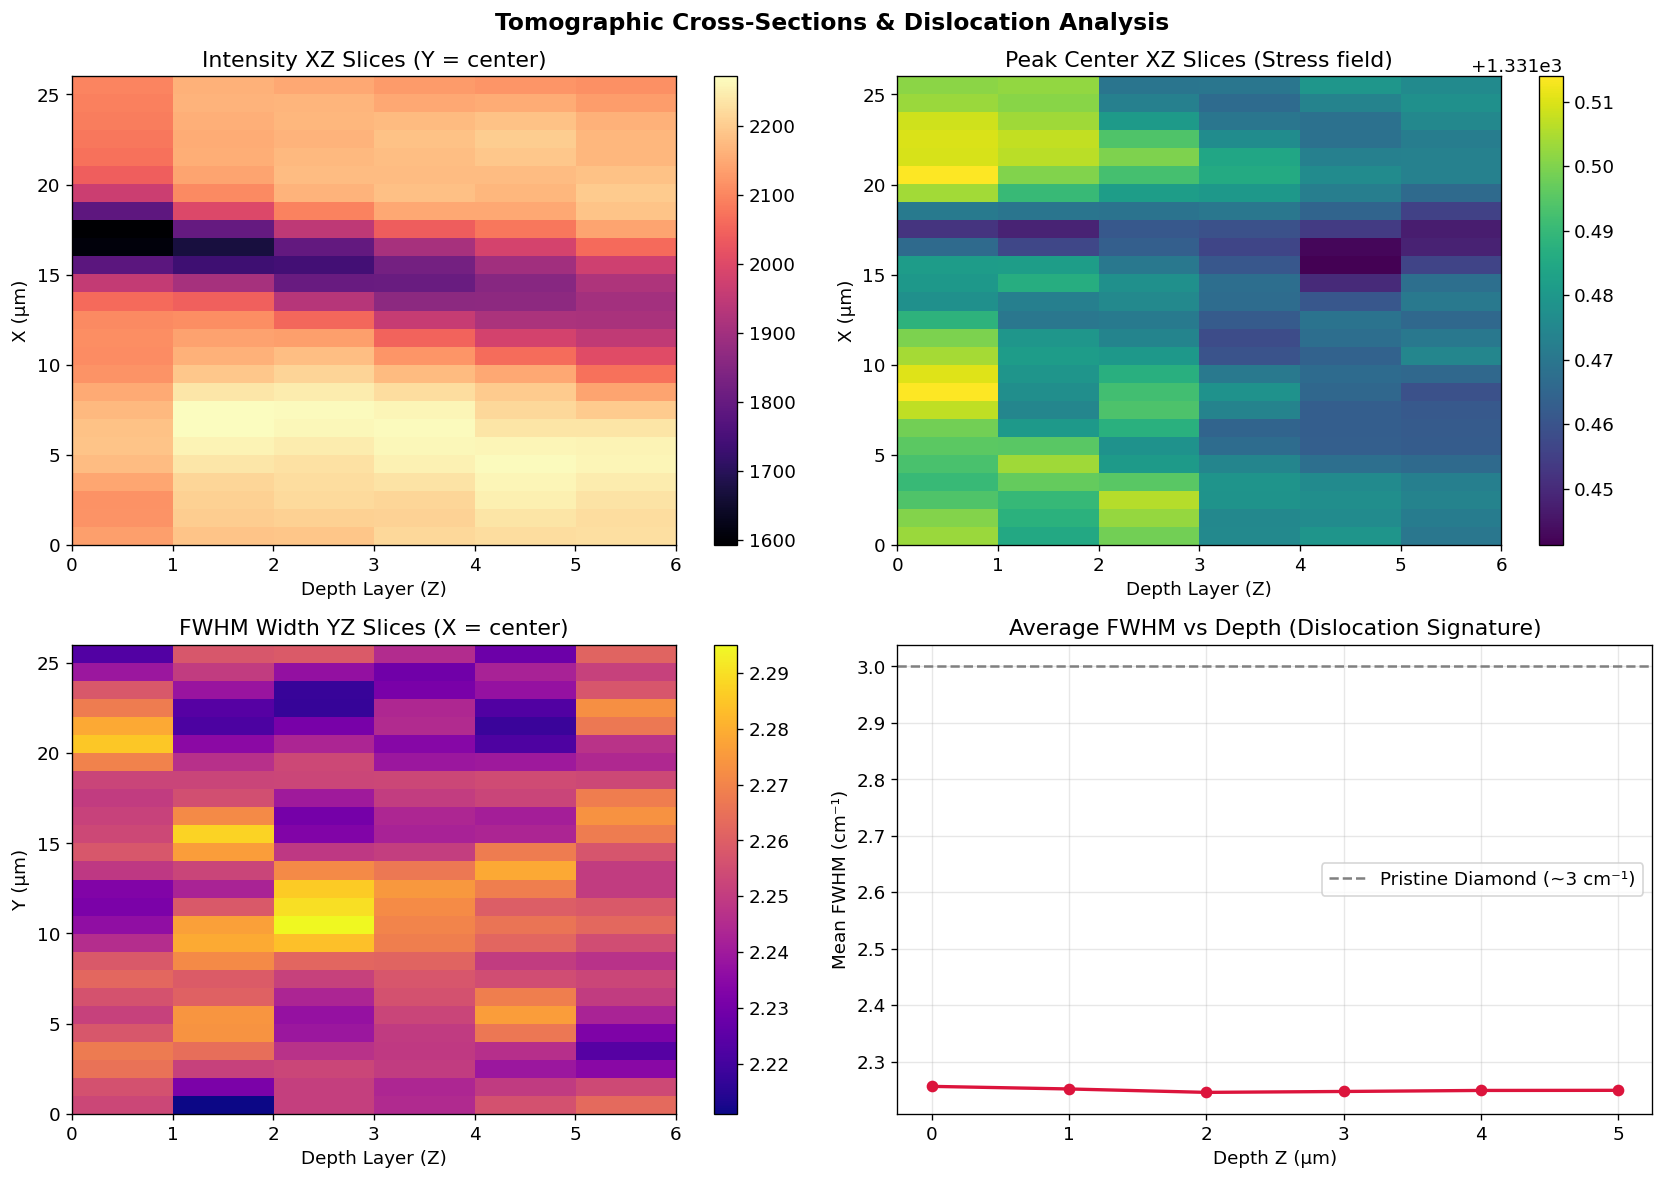

In [7]:
if 'results' in locals() and results['intensity'].shape[0] > 1:
    z_depth, grid_y, grid_x = results['intensity'].shape
    y_mid, x_mid = grid_y // 2, grid_x // 2
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # XZ cross-section through center Y
    xz_int = results['intensity'][:, y_mid, :].T  # (X, Z)
    im0 = axes[0, 0].imshow(xz_int, aspect='auto', origin='lower', cmap='magma', extent=[0, z_depth, 0, grid_x])
    axes[0, 0].set_title('Intensity XZ Slices (Y = center)')
    axes[0, 0].set_xlabel('Depth Layer (Z)')
    axes[0, 0].set_ylabel('X (µm)')
    plt.colorbar(im0, ax=axes[0, 0])
    
    # XZ cross-section for peak shift (Stress)
    xz_pos = results['position'][:, y_mid, :].T
    im1 = axes[0, 1].imshow(xz_pos, aspect='auto', origin='lower', cmap='viridis', extent=[0, z_depth, 0, grid_x])
    axes[0, 1].set_title('Peak Center XZ Slices (Stress field)')
    axes[0, 1].set_xlabel('Depth Layer (Z)')
    axes[0, 1].set_ylabel('X (µm)')
    plt.colorbar(im1, ax=axes[0, 1])
    
    # YZ cross-section for FWHM Width (Defects)
    yz_width = results['width'][:, :, x_mid].T  # (Y, Z)
    im2 = axes[1, 0].imshow(yz_width, aspect='auto', origin='lower', cmap='plasma', extent=[0, z_depth, 0, grid_y])
    axes[1, 0].set_title('FWHM Width YZ Slices (X = center)')
    axes[1, 0].set_xlabel('Depth Layer (Z)')
    axes[1, 0].set_ylabel('Y (µm)')
    plt.colorbar(im2, ax=axes[1, 0])
    
    # Dislocation Core Depth Profile (Min Intensity / Max Width)
    mean_width_depth = np.mean(results['width'], axis=(1, 2))
    depths_um = np.arange(z_depth) * 1.0  # 1 mkm step
    
    axes[1, 1].plot(depths_um, mean_width_depth, 'o-', color='crimson', lw=2)
    axes[1, 1].axhline(3.0, color='gray', linestyle='--', label='Pristine Diamond (~3 cm⁻¹)')
    axes[1, 1].set_title('Average FWHM vs Depth (Dislocation Signature)')
    axes[1, 1].set_xlabel('Depth Z (µm)')
    axes[1, 1].set_ylabel('Mean FWHM (cm⁻¹)')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()
    
    plt.suptitle('Tomographic Cross-Sections & Dislocation Analysis', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()